# Douro Paradox

Flag: **`SIGMOID_DISTANCE_FROM_PORTO_KM`**

Pooled, the new drip irrigation wins. Split by distance from Porto (near / far, cut at 110 km) the old method wins in both groups.

## 1. Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

sns.set_theme(style='whitegrid')
df = pd.read_csv('douro_vineyard_data.csv')
print(df.shape)
df.head()

(3543, 17)


,plot_id,treatment,soil_depth_cm,trellis_system,vineyard_age_group,sun_hours_july,vine_density_per_ha,cooperative,annual_rainfall_mm,grape_variety,distance_from_porto_km,organic_certified,elevation_m,soil_ph,harvest_month,slope_aspect,harvest_success
0,DV-00001,control,127.0,bush vine,mature (15-40y),341.0,5100.0,COOP-11,835.0,Touriga Nacional,185.7,no,280.6,6.50,October,north-facing,0
1,DV-00002,treatment,122.0,bush vine,mature (15-40y),289.0,3633.0,COOP-12,554.0,Tinta Roriz,138.0,no,232.6,6.26,September,north-facing,0
2,DV-00003,treatment,132.0,vertical shoot positioning,young (<15y),336.0,4055.0,COOP-11,679.0,Touriga Franca,181.5,no,421.1,6.22,September,east-facing,0
3,DV-00004,control,49.0,vertical shoot positioning,mature (15-40y),324.0,4397.0,COOP-05,638.0,Touriga Franca,123.5,no,205.7,6.13,October,west-facing,1
4,DV-00005,treatment,153.0,lyre,old (>40y),340.0,4567.0,COOP-05,513.0,Tinta Roriz,96.8,yes,260.9,6.01,October,east-facing,1


In [2]:
print('missing:', df.isna().sum().sum())
print('duplicate plot_id:', df['plot_id'].duplicated().sum())
df.dtypes.value_counts()

missing: 0
duplicate plot_id: 0


object     9
float64    7
int64      1
Name: count, dtype: int64

In [3]:
num_cols = ['soil_depth_cm', 'sun_hours_july', 'vine_density_per_ha', 'annual_rainfall_mm',
            'distance_from_porto_km', 'elevation_m', 'soil_ph']
cat_cols = ['trellis_system', 'vineyard_age_group', 'cooperative', 'grape_variety',
            'organic_certified', 'harvest_month', 'slope_aspect']
df[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
soil_depth_cm,3543.0,98.70,41.72,40.00,56.00,114.00,138.00,160.00
sun_hours_july,3543.0,340.41,24.56,250.00,324.00,340.00,357.00,441.00
vine_density_per_ha,3543.0,4506.01,606.16,2500.00,4087.50,4512.00,4918.00,6637.00
annual_rainfall_mm,3543.0,651.75,120.83,250.00,570.00,654.00,732.00,1040.00
distance_from_porto_km,3543.0,131.03,40.80,70.00,92.20,131.10,165.50,204.90
elevation_m,3543.0,221.82,69.79,40.00,174.20,221.60,269.80,451.60
soil_ph,3543.0,6.30,0.34,5.19,6.07,6.31,6.53,7.58


## 2. Treatment vs control, pooled

In [4]:
overall = df.groupby('treatment')['harvest_success'].agg(plots='count', successes='sum', rate='mean')
overall

,plots,successes,rate
treatment,,,
control,1653,447,0.270417
treatment,1890,585,0.309524


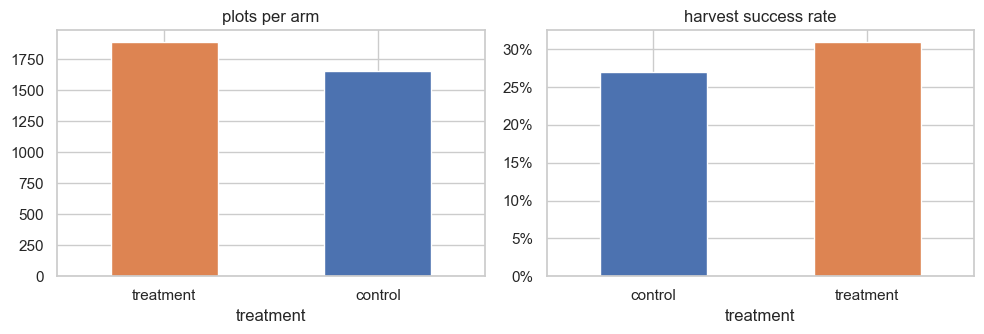

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
df['treatment'].value_counts().plot.bar(ax=ax[0], color=['#dd8452', '#4c72b0'], rot=0)
ax[0].set_title('plots per arm')
overall['rate'].plot.bar(ax=ax[1], color=['#4c72b0', '#dd8452'], rot=0)
ax[1].set_title('harvest success rate')
ax[1].yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
plt.tight_layout(); plt.show()

Treatment 31.0% vs control 27.0%, about +4 points. Arms are not the same size (1890 vs 1653).

## 3. EDA: numeric columns by arm

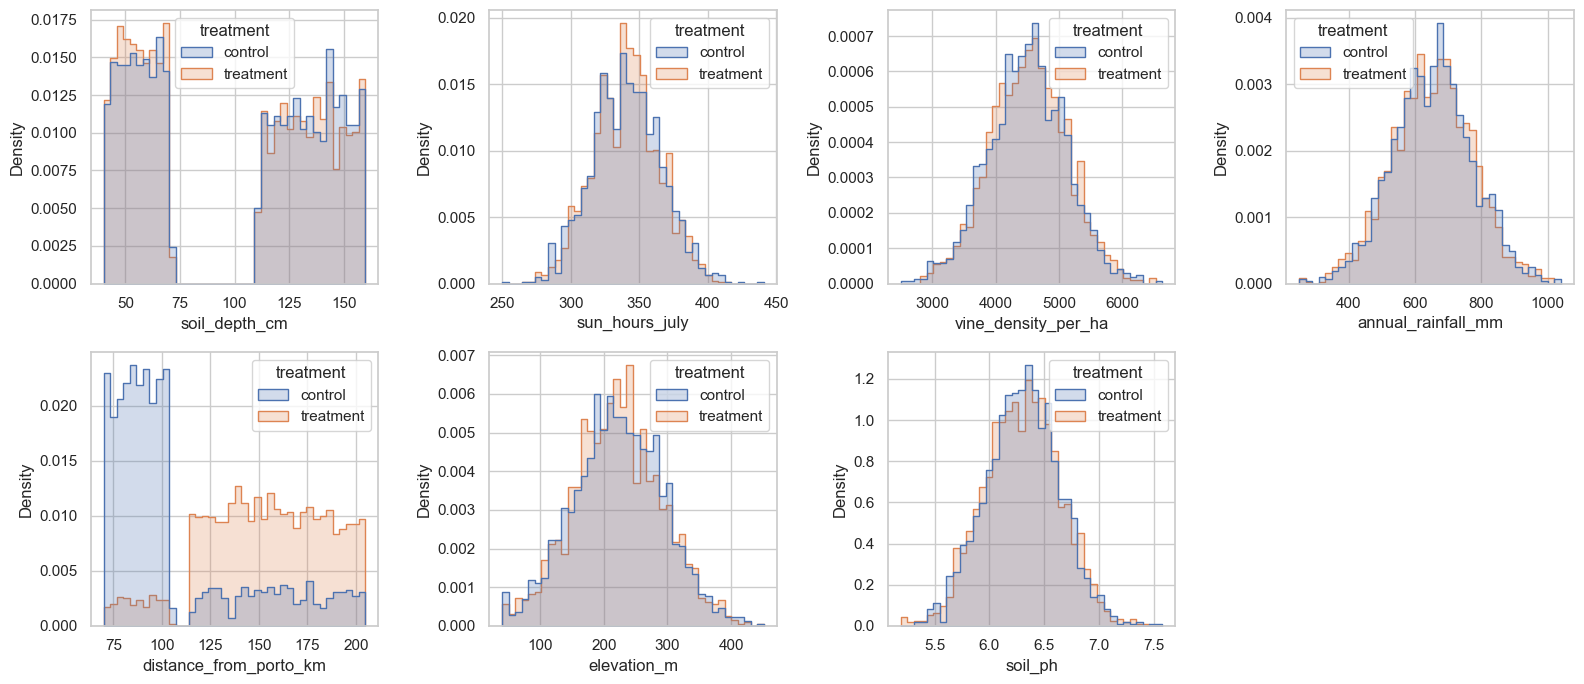

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.flat, num_cols):
    sns.histplot(df, x=c, hue='treatment', stat='density', common_norm=False,
                 element='step', bins=40, ax=ax)
axes.flat[-1].axis('off')
plt.tight_layout(); plt.show()

Everything overlaps between the arms except `distance_from_porto_km`: it has two clusters, and treatment plots sit mostly in the far one.

## 4. EDA: categorical columns

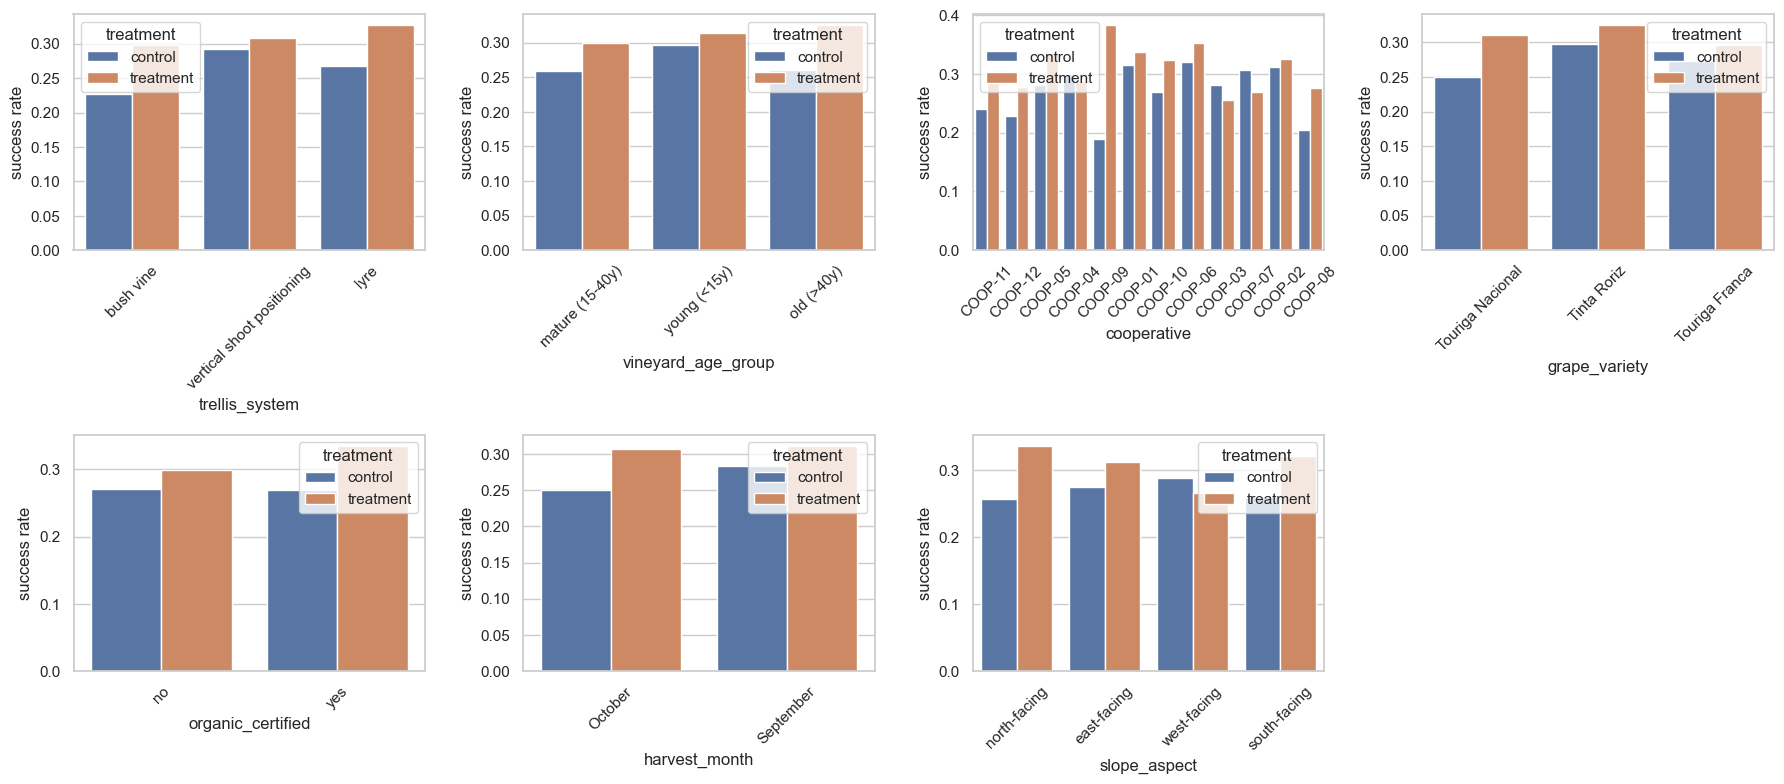

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.flat, cat_cols):
    sns.barplot(df, x=c, y='harvest_success', hue='treatment', errorbar=None, ax=ax)
    ax.tick_params(axis='x', rotation=45)
    ax.set_ylabel('success rate')
axes.flat[-1].axis('off')
plt.tight_layout(); plt.show()

In [8]:
share = {c: df.groupby(c)['treatment'].apply(lambda s: (s == 'treatment').mean()) for c in cat_cols}
pd.DataFrame({c: [s.min(), s.max()] for c, s in share.items()}, index=['min treat share', 'max treat share']).T.round(2)

,min treat share,max treat share
trellis_system,0.53,0.54
vineyard_age_group,0.52,0.54
cooperative,0.49,0.58
grape_variety,0.53,0.54
organic_certified,0.53,0.53
harvest_month,0.51,0.55
slope_aspect,0.52,0.55


Treatment share is about the same (0.49-0.58) in every category, so none of these can explain the pooled gap. Treatment is ahead in almost all of the bars.

## 5. Correlations and balance

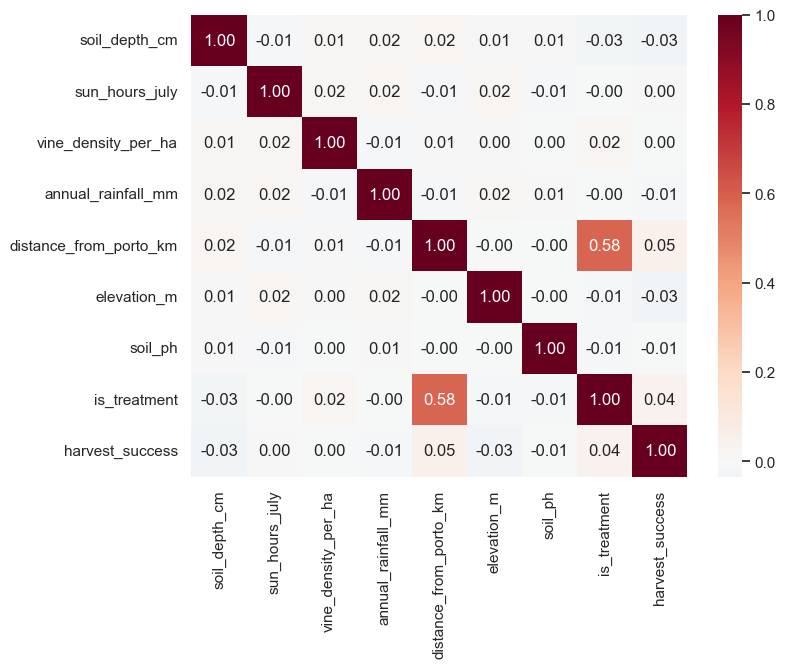

In [9]:
df['is_treatment'] = (df['treatment'] == 'treatment').astype(int)
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols + ['is_treatment', 'harvest_success']].corr(), annot=True, fmt='.2f',
            cmap='RdBu_r', center=0)
plt.show()

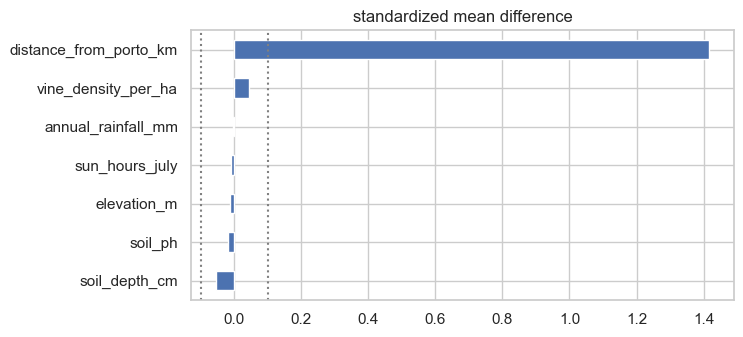

soil_depth_cm            -0.054
sun_hours_july           -0.009
vine_density_per_ha       0.045
annual_rainfall_mm       -0.003
distance_from_porto_km    1.417
elevation_m              -0.013
soil_ph                  -0.017
dtype: float64

In [10]:
# standardized mean difference treatment vs control, usual balance check for experiments
t, c = df[df.is_treatment == 1], df[df.is_treatment == 0]
smd = (t[num_cols].mean() - c[num_cols].mean()) / np.sqrt((t[num_cols].var() + c[num_cols].var()) / 2)
smd.sort_values().plot.barh(figsize=(7, 3.5), title='standardized mean difference')
plt.axvline(0.1, color='grey', ls=':'); plt.axvline(-0.1, color='grey', ls=':')
plt.show()
smd.round(3)

Distance is the only unbalanced column (SMD about 1.4, the rest are near 0). So the arms differ in where the plots are.

## 6. Looking for the reversal

In [11]:
def control_wins(groups):
    r = df.assign(g=groups).pivot_table(index='g', columns='treatment',
                                        values='harvest_success', aggfunc='mean', observed=True)
    return int((r['control'] > r['treatment']).sum()), len(r)

rows = [(c, 'categories', *control_wins(df[c])) for c in cat_cols]
for c in num_cols:
    for q in (2, 3, 4, 5, 10):
        rows.append((c, f'{q} quantile bins', *control_wins(pd.qcut(df[c], q))))
res = pd.DataFrame(rows, columns=['column', 'split', 'control_wins', 'groups'])
res['full_reversal'] = res.control_wins == res.groups
res[res.full_reversal | (res.control_wins > 0)]

,column,split,control_wins,groups,full_reversal
2,cooperative,categories,3,12,False
6,slope_aspect,categories,1,4,False
10,soil_depth_cm,5 quantile bins,1,5,False
11,soil_depth_cm,10 quantile bins,2,10,False
16,sun_hours_july,10 quantile bins,1,10,False
19,vine_density_per_ha,4 quantile bins,1,4,False
21,vine_density_per_ha,10 quantile bins,3,10,False
25,annual_rainfall_mm,5 quantile bins,1,5,False
26,annual_rainfall_mm,10 quantile bins,2,10,False
27,distance_from_porto_km,2 quantile bins,1,2,False


No category gives a full reversal (`cooperative` 3/12, `slope_aspect` 1/4). Quantile bins don't either, but distance has by far the most groups where control wins. Quantile cuts ignore the shape of the data, so let's look at distance directly.

In [12]:
s = np.sort(df['distance_from_porto_km'].unique())
gaps = pd.Series(np.diff(s), index=s[:-1]).sort_values(ascending=False)
gaps.head(3)

104.0    10.0
164.0     0.3
185.1     0.3
dtype: float64

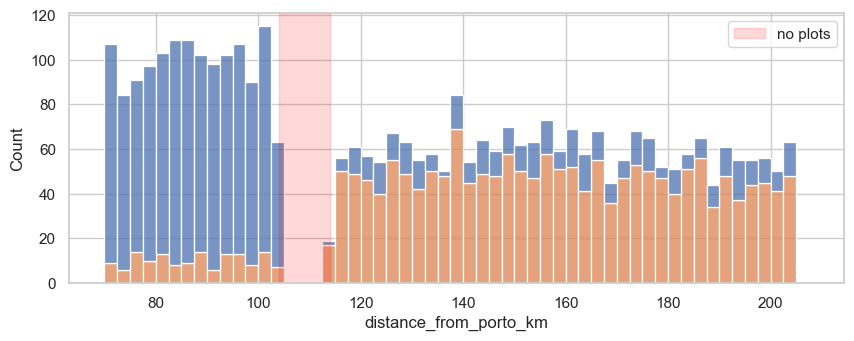

In [13]:
plt.figure(figsize=(10, 3.5))
sns.histplot(df, x='distance_from_porto_km', hue='treatment', bins=np.arange(70, 210, 2.5), multiple='stack')
plt.axvspan(104, 114, color='red', alpha=0.15, label='no plots')
plt.legend(); plt.show()

Nothing between 104 and 114 km. Two clusters, so the natural cut is 110 km.

`soil_depth_cm` also has a gap (nothing between 70 and 110 cm, see section 3), so check that one too:

In [14]:
soil = np.where(df['soil_depth_cm'] < 90, 'shallow', 'deep')
df.assign(soil=soil).pivot_table(index='soil', columns='treatment', values='harvest_success', aggfunc='mean')

treatment,control,treatment
soil,,
deep,0.264069,0.285005
shallow,0.278464,0.337486


Treatment wins on both sides of the soil gap, so soil depth is not it.

## 7. Feature engineering

In [15]:
df['distance_group'] = np.where(df['distance_from_porto_km'] < 110, 'near', 'far')
df['distance_band'] = pd.cut(df['distance_from_porto_km'], np.arange(70, 215, 10), right=False)

band = df.groupby('distance_band', observed=True).agg(
    plots=('harvest_success', 'size'),
    treat_share=('is_treatment', 'mean'),
    success=('harvest_success', 'mean'))
band.round(3)

,plots,treat_share,success
distance_band,,,
"[70, 80)",379,0.103,0.282
"[80, 90)",423,0.104,0.251
"[90, 100)",397,0.101,0.244
"[100, 110)",178,0.118,0.213
"[110, 120)",136,0.853,0.324
"[120, 130)",241,0.788,0.332
"[130, 140)",247,0.846,0.312
"[140, 150)",247,0.810,0.340
"[150, 160)",257,0.802,0.288


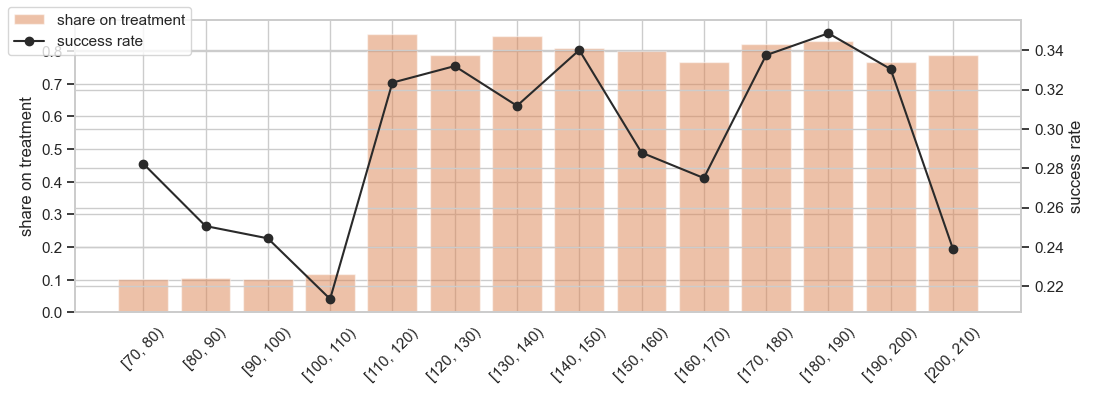

In [16]:
fig, ax = plt.subplots(figsize=(11, 4))
x = band.index.astype(str)
ax.bar(x, band['treat_share'], color='#dd8452', alpha=0.5, label='share on treatment')
ax2 = ax.twinx()
ax2.plot(x, band['success'], 'o-', color='#2a2a2a', label='success rate')
ax.set_ylabel('share on treatment'); ax2.set_ylabel('success rate')
ax.tick_params(axis='x', rotation=45)
fig.legend(loc='upper left'); plt.tight_layout(); plt.show()

Past 110 km about 80% of plots are on treatment, and success is higher there for everyone.

## 8. Result

In [17]:
tab = df.pivot_table(index='distance_group', columns='treatment', values='harvest_success', aggfunc='mean')
tab['treatment - control'] = tab['treatment'] - tab['control']
tab.loc['all (pooled)'] = [overall.loc['control', 'rate'], overall.loc['treatment', 'rate'],
                           overall.loc['treatment', 'rate'] - overall.loc['control', 'rate']]
tab.style.format('{:.1%}')

treatment,control,treatment,treatment - control
distance_group,,,
far,32.1%,31.4%,-0.7%
near,25.3%,25.0%,-0.3%
all (pooled),27.0%,31.0%,3.9%


In [18]:
pd.crosstab(df['distance_group'], df['treatment'], margins=True)

treatment,control,treatment,All
distance_group,,,
far,420,1746,2166
near,1233,144,1377
All,1653,1890,3543


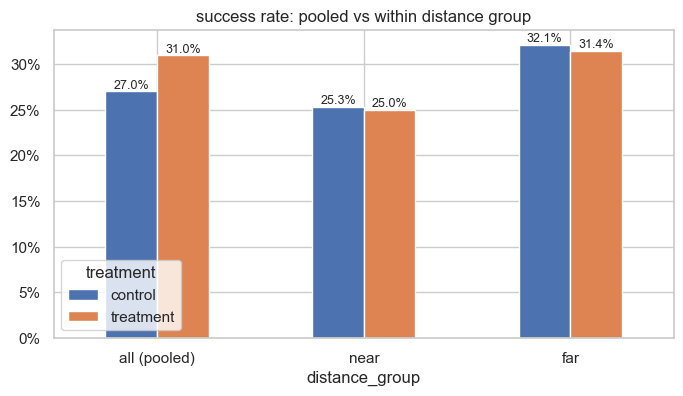

In [19]:
plot = tab[['control', 'treatment']].reindex(['all (pooled)', 'near', 'far'])
ax = plot.plot.bar(figsize=(8, 4), rot=0, color=['#4c72b0', '#dd8452'])
for p in ax.patches:
    ax.annotate(f'{p.get_height():.1%}', (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=9)
ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
ax.set_title('success rate: pooled vs within distance group')
plt.show()

Same thing with logistic regression: the treatment coefficient flips sign once distance group is in the model.

In [20]:
m1 = smf.logit('harvest_success ~ is_treatment', df).fit(disp=0)
m2 = smf.logit('harvest_success ~ is_treatment + C(distance_group)', df).fit(disp=0)
pd.DataFrame({'pooled': m1.params, '+ distance_group': m2.params}).round(3)

,pooled,+ distance_group
C(distance_group)[T.near],NaN,-0.331
Intercept,-0.993,-0.750
is_treatment,0.190,-0.028


## Why

The new method was mostly tried on far plots (81% of them vs 10% of near ones), and far plots succeed more often with either method, so pooling gives treatment credit for where it was used.